<span style="font-weight: bold; font-size: 50px; color: rgba(199, 177, 12, 1);"> Frequency domain analysis : </span> <br>
<span style="font-size: 35px"> Comparing different signals in the frequency domain (+ filter and process) </span>

In [2]:
import numpy as np

# prefix_path = r"F:\GeorgiaTech\Programming\Ceramic_processing\Data"
prefix_path = r"\\10.29.58.4\umi2958-users\GTL\hcherid\Windows\Programming_Data\Ceramic_processing"

x_shape_list = np.load(fr"{prefix_path}/x_shape_list.npy")
y_shape_list = np.load(fr"{prefix_path}/y_shape_list.npy")
file_list = np.load(fr"{prefix_path}/file_list.npy")

ROI_arr = np.load(fr"{prefix_path}/ROI_arr.npy")

C:\Users\hcherid\AppData\Local\Temp\ipykernel_14212\2873846051.py:149: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


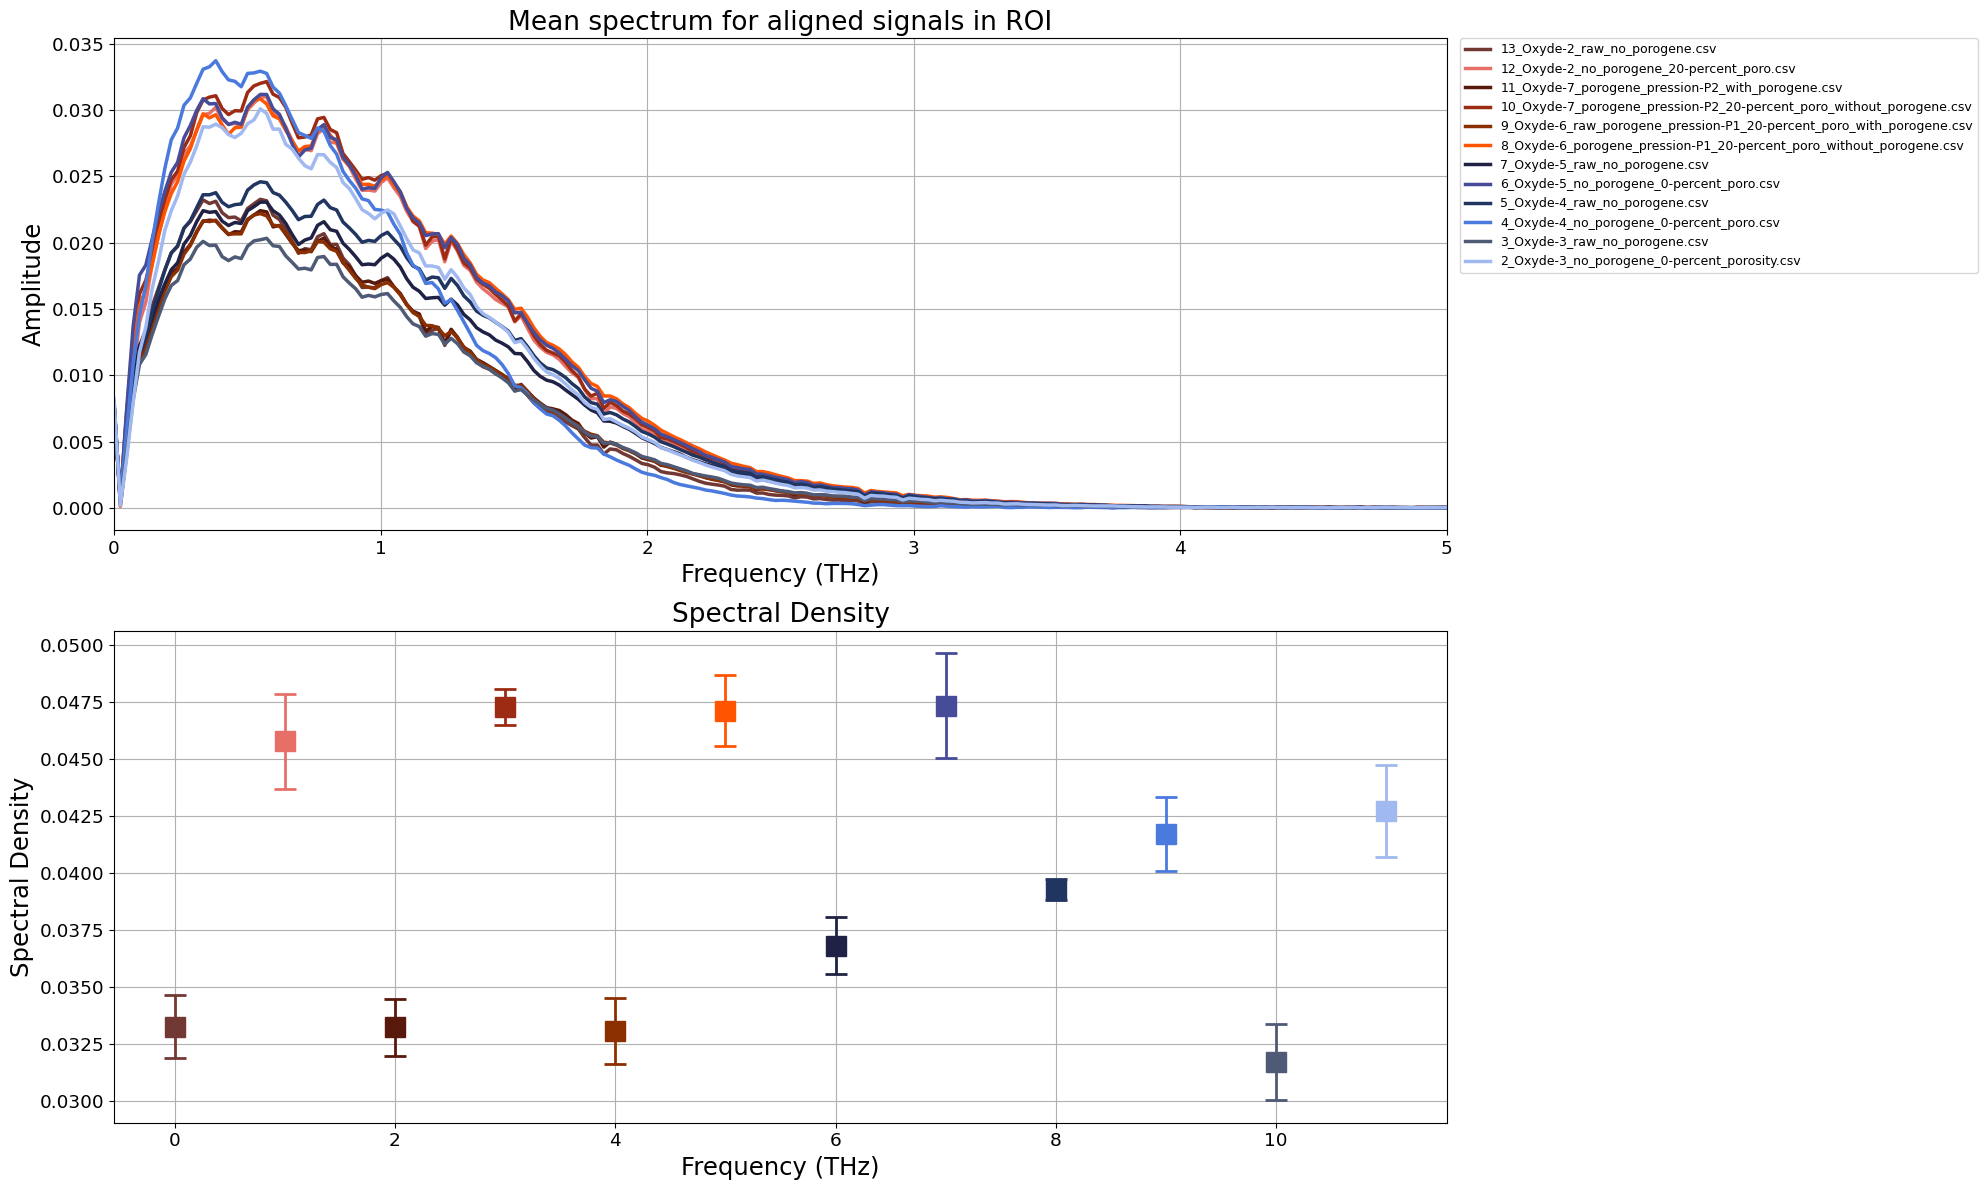

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from scipy.fft import fft, fftfreq
from scipy.integrate import simpson

dt_ps = 0.020464 

n_samples = ROI_arr.shape[0]
T = ROI_arr.shape[-1]
colors = [
    "#ba1b1b",  # 14_composite_20-percent_poro 0
    "#723834",  # 13_Oxyde-2_raw_no_porogene 1
    "#e67068",  # 12_Oxyde-2_no_porogene_20-percent_poro 2
    "#58190C",  # 11_Oxyde-7_porogene_pression-P2_with_porogene 3
    "#342D69",  # 1_Oxyde-1_no_porogene_0-percent_porosity 4
    "#9d2b14",  # 10_Oxyde-7_porogene_pression-P2_20-percent_poro_without_porogene 5
    "#8c2f00",  # 9_Oxyde-6_raw_porogene_pression-P1_20-percent_poro_with_porogene 6
    "#ff5500",  # 8_Oxyde-6_porogene_pression-P1_20-percent_poro_without_porogene 7
    "#202245",  # 7_Oxyde-5_raw_no_porogene 8
    "#474c99",  # 6_Oxyde-5_no_porogene_0-percent_poro 9
    "#213561",  # 5_Oxyde-4_raw_no_porogene 10
    "#4F5B76",  # 3_Oxyde-3_raw_no_porogene 11
    "#4b7ade",  # 4_Oxyde-4_no_porogene_0-percent_poro 12
    "#843c39",  # 3_Oxyde-3_raw_no_porogene_no_focus 13
    "#A0B9F0",  # 2_Oxyde-3_no_porogene_0-percent_porosity 14
    "#3182bd",  # 1_Oxyde-1_no_porogene_0-percent_porosity_old_holder 15
]

diameter = [1, 11.88, 11.88, 25.02, 25.02, 25.02, 24.86, 24.86, 24.85, 24.85, 11.05, 10.97, 11.05, 10.97, 10.97, 25.02]
height = [1, 9.37, 9.37, 7.80, 15.66, 7.80, 7.2, 7.2, 7.37, 7.37, 12.44, 6.68, 12.44, 6.68, 6.68, 15.66]

sample_list = [4, 9, 12, 14] #  Heated samples influence of diameter and height
# sample_list = [0, 2, 5, 7, 4] # Heatd internal porosity and porogene changes
sample_list = [1, 2, 3, 5, 6, 7, 8, 9, 10, 12, 11, 14] # Heatd vs raw


mean_signals = []
signals_alligned_all = []
for i in sample_list:
    signals = ROI_arr[i].reshape(-1, T)

    signals_aligned = []
    cpt = 0

    max_sample = np.argmax(signals.max(axis=1))
    ref_peak = np.argmax(signals[max_sample])
    ref_max = np.max(signals[max_sample])
    
    for signal in signals : 
        shift = ref_peak - np.argmax(signal)
        max = np.max(signal)

        if max > 0.8*ref_max and max < 1.2*ref_max:
            signals_aligned.append(np.roll(signal, shift))
    
        cpt +=1
    signals_aligned = np.array(signals_aligned)
    signals_alligned_all.append(signals_aligned)
    mean_signals.append(signals_aligned.mean(axis=0))

mean_signals = np.array(mean_signals)

t = np.arange(T)*dt_ps

fig, ax = plt.subplots(2,1,figsize=(20, 12))

ref_peak = np.argmax(mean_signals[0])

# sample spacing
x = np.linspace(0.0, T*dt_ps, T, endpoint=False)

cpt = 0
for i in sample_list:
    color = colors[i]
    label = file_list[i].split("\\")[-1]

    # Re-compute std on the aligned pixel-level signals for the variance band
    shift = ref_peak - np.argmax(mean_signals[cpt])
    mean_signal = np.roll(mean_signals[cpt], shift, axis=0)
    std_signal = signals_aligned.std(axis=0)

    # Number of sample points
    yf = fft(mean_signal)
    xf = fftfreq(T, dt_ps)[:T//2]

    ax[0].plot(xf, 2.0/T * np.abs(yf[0:T//2]), 
    color=color, linewidth=2.5, label=label)
    # plt.fill_between(t,
    #                  mean_signal - std_signal,
    #                  mean_signal + std_signal,
    #                  color=color, alpha=0.25)


    # DSP
    DSP_list = []
    for signal in signals_alligned_all[cpt]:
        yf = 2.0/T * np.abs(fft(signal)[0:T//2])
        xf = fftfreq(T, dt_ps)[:T//2]

        DSP = simpson(yf, xf)
        DSP_list.append(DSP)

    DSP_arr = np.array(DSP_list)

    ax[1].errorbar(
        cpt, DSP_arr.mean(),
        yerr=DSP_arr.std(),
        fmt='s',                  
        markersize=15,
        color=color,
        ecolor=color,             
        elinewidth=2,             
        capsize=8,                
        capthick=2,               
        label=label
    )

    
    cpt +=1

# Global mean across all aligned sample means
# global_mean = aligned_signals.mean(axis=0)
# plt.plot(t, global_mean, color='black', linewidth=2,
#          linestyle='--', label='Global mean (aligned)')

# plt.axvline(ref_peak, color='grey', linestyle=':', linewidth=1.2,
#             label=f'Ref peak (t={ref_peak})')
FONT_SIZE = 19

ax[0].set_title("Mean spectrum for aligned signals in ROI", fontsize = FONT_SIZE)
ax[0].set_xlabel("Frequency (THz)", fontsize = FONT_SIZE*0.92)
ax[0].set_ylabel("Amplitude", fontsize = FONT_SIZE*0.92)
ax[0].legend(fontsize=9, bbox_to_anchor=(1.01, 1), loc='upper left', borderaxespad=0)
ax[0].set_xlim([0,5])
ax[0].tick_params(axis='x', which='major', labelsize=FONT_SIZE*0.7)
ax[0].tick_params(axis='y', which='major', labelsize=FONT_SIZE*0.7)
# plt.yscale('log')
ax[0].grid()

ax[1].set_title("Spectral Density", fontsize = FONT_SIZE)
ax[1].set_xlabel("Frequency (THz)", fontsize = FONT_SIZE*0.92)
ax[1].set_ylabel("Spectral Density", fontsize = FONT_SIZE*0.92)
ax[1].tick_params(axis='x', which='major', labelsize=FONT_SIZE*0.7)
ax[1].tick_params(axis='y', which='major', labelsize=FONT_SIZE*0.7)
ax[1].grid()

plt.tight_layout()
fig.show()


C:\Users\Hugo\AppData\Local\Temp\ipykernel_42244\880557609.py:150: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


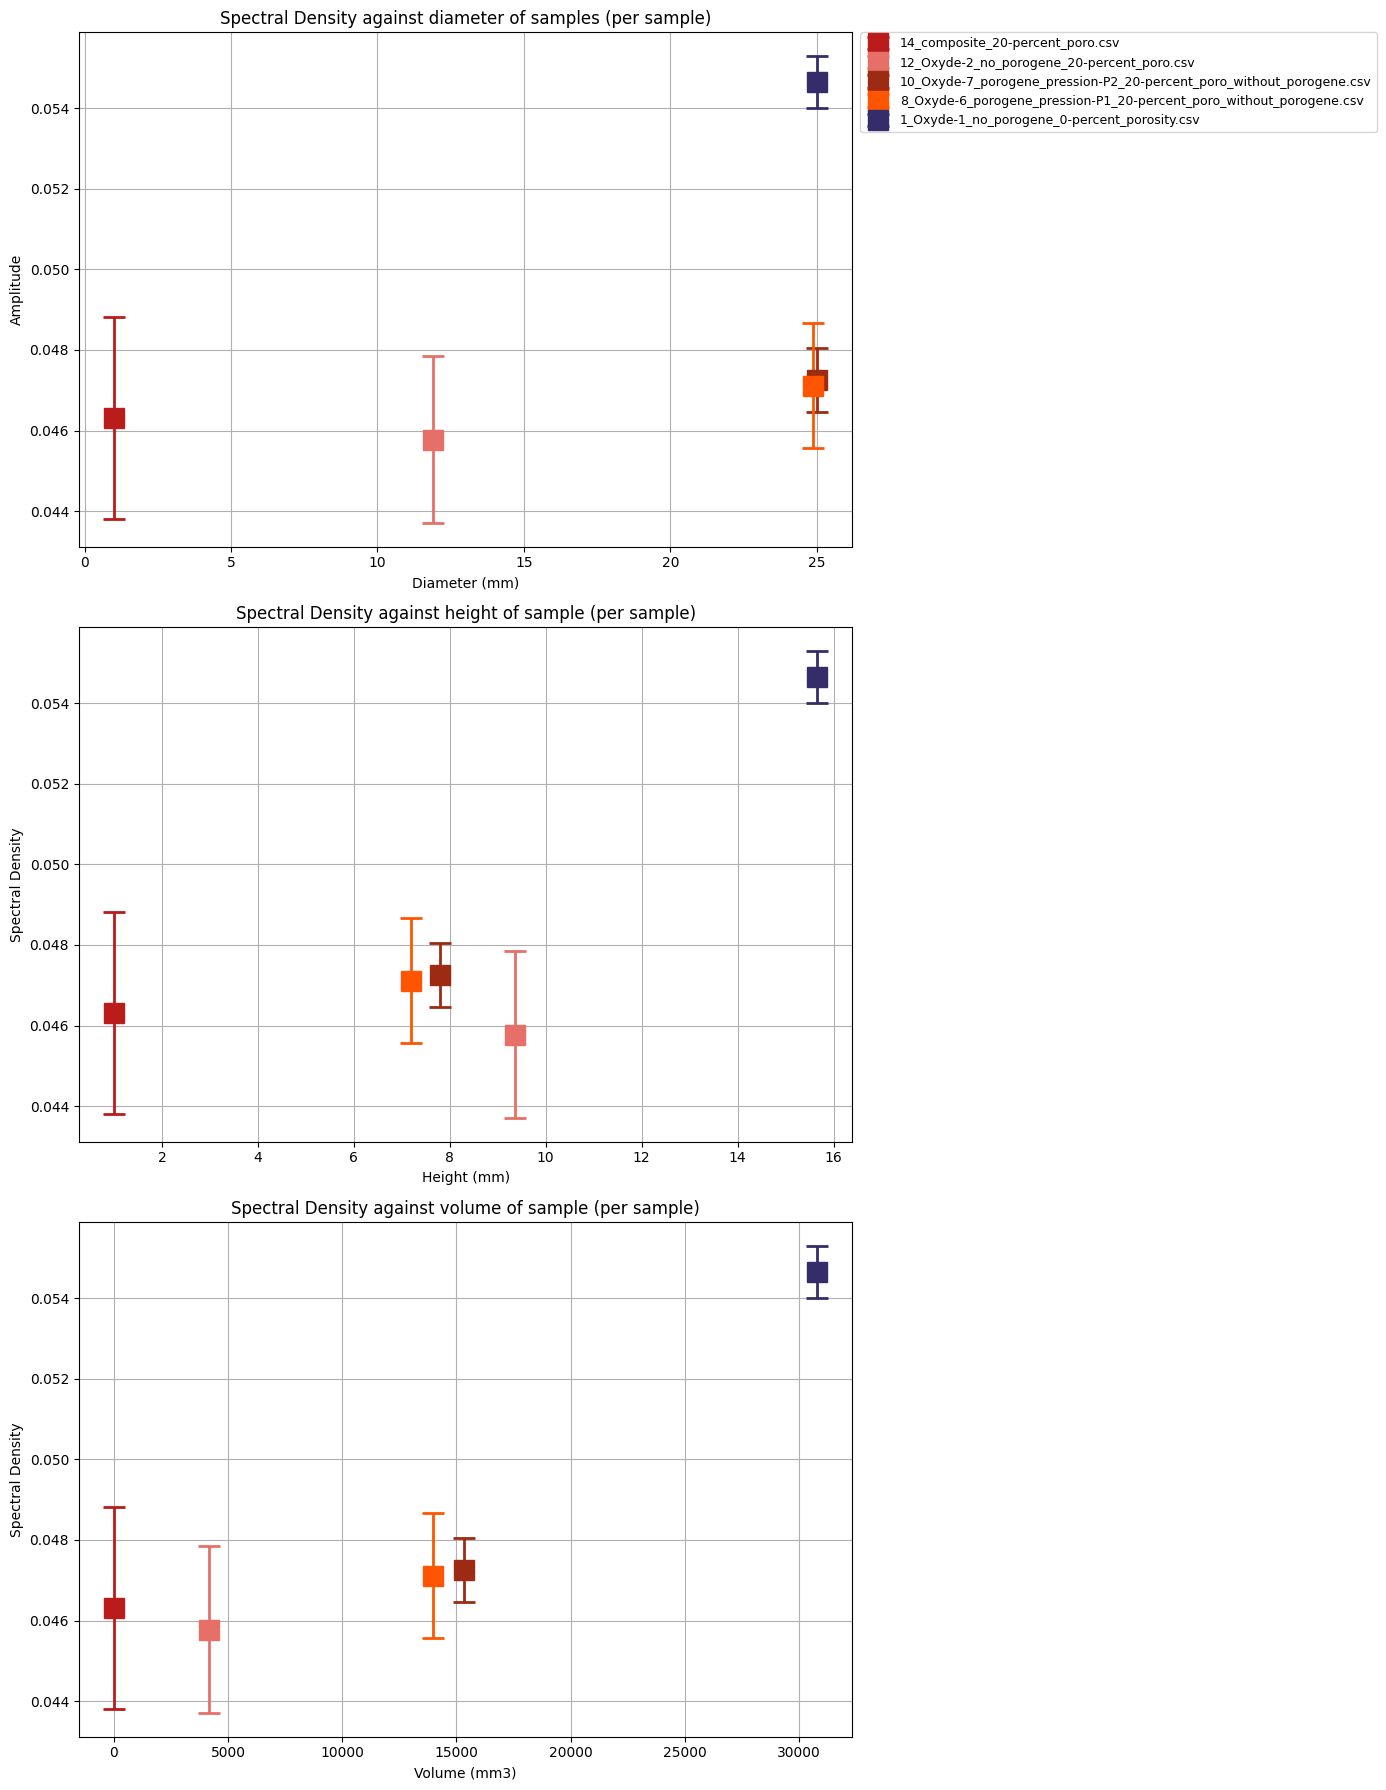

In [43]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from scipy.fft import fft, fftfreq
from scipy.integrate import simpson

dt_ps = 0.020464 

n_samples = ROI_arr.shape[0]
T = ROI_arr.shape[-1]
colors = [
    "#ba1b1b",  # 14_composite_20-percent_poro 0
    "#723834",  # 13_Oxyde-2_raw_no_porogene 1
    "#e67068",  # 12_Oxyde-2_no_porogene_20-percent_poro 2
    "#58190C",  # 11_Oxyde-7_porogene_pression-P2_with_porogene 3
    "#342D69",  # 1_Oxyde-1_no_porogene_0-percent_porosity 4
    "#9d2b14",  # 10_Oxyde-7_porogene_pression-P2_20-percent_poro_without_porogene 5
    "#8c2f00",  # 9_Oxyde-6_raw_porogene_pression-P1_20-percent_poro_with_porogene 6
    "#ff5500",  # 8_Oxyde-6_porogene_pression-P1_20-percent_poro_without_porogene 7
    "#202245",  # 7_Oxyde-5_raw_no_porogene 8
    "#474c99",  # 6_Oxyde-5_no_porogene_0-percent_poro 9
    "#213561",  # 5_Oxyde-4_raw_no_porogene 10
    "#4F5B76",  # 3_Oxyde-3_raw_no_porogene 11
    "#4b7ade",  # 4_Oxyde-4_no_porogene_0-percent_poro 12
    "#843c39",  # 3_Oxyde-3_raw_no_porogene_no_focus 13
    "#A0B9F0",  # 2_Oxyde-3_no_porogene_0-percent_porosity 14
    "#3182bd",  # 1_Oxyde-1_no_porogene_0-percent_porosity_old_holder 15
]

diameter = [1, 11.88, 11.88, 25.02, 25.02, 25.02, 24.86, 24.86, 24.85, 24.85, 11.05, 10.97, 11.05, 10.97, 10.97, 25.02]
height = [1, 9.37, 9.37, 7.80, 15.66, 7.80, 7.2, 7.2, 7.37, 7.37, 12.44, 6.68, 12.44, 6.68, 6.68, 15.66]

sample_list = [4, 9, 12, 14] #  Heated samples influence of diameter and height
sample_list = [0, 2, 5, 7, 4] # Heatd internal porosity and porogene changes
# sample_list = [1, 2, 3, 5, 6, 7, 8, 9, 10, 12, 11, 14] # Heatd vs raw


signals_alligned_all = []
for i in sample_list:
    signals = ROI_arr[i].reshape(-1, T)

    signals_aligned = []
    cpt = 0

    max_sample = np.argmax(signals.max(axis=1))
    ref_peak = np.argmax(signals[max_sample])
    ref_max = np.max(signals[max_sample])
    
    for signal in signals : 
        shift = ref_peak - np.argmax(signal)
        max = np.max(signal)

        if max > 0.8*ref_max and max < 1.2*ref_max:
            signals_aligned.append(np.roll(signal, shift))
    
        cpt +=1
    signals_aligned = np.array(signals_aligned)
    signals_alligned_all.append(signals_aligned)


fig, ax = plt.subplots(3,1,figsize=(14, 18))

cpt = 0
for i in sample_list:
    color = colors[i]
    label = file_list[i].split("\\")[-1]


    # DSP
    DSP_list = []
    for signal in signals_alligned_all[cpt]:

        yf = 2.0/T * np.abs(fft(signal)[0:T//2])
        xf = fftfreq(T, dt_ps)[:T//2]

        DSP = simpson(yf, xf)
        DSP_list.append(DSP)

    DSP_arr = np.array(DSP_list)

    ax[0].errorbar(
        diameter[i], DSP_arr.mean(),
        yerr=DSP_arr.std(),
        fmt='s',                  
        markersize=15,
        color=color,
        ecolor=color,             
        elinewidth=2,             
        capsize=8,                
        capthick=2,               
        label=label
    )

    ax[1].errorbar(
        height[i], DSP_arr.mean(),
        yerr=DSP_arr.std(),
        fmt='s',                  
        markersize=15,
        color=color,
        ecolor=color,             
        elinewidth=2,             
        capsize=8,                
        capthick=2,               
        label=label
    )

    ax[2].errorbar(
        np.pi * height[i] * diameter[i]**2, DSP_arr.mean(),
        yerr=DSP_arr.std(),
        fmt='s',                  
        markersize=15,
        color=color,
        ecolor=color,             
        elinewidth=2,             
        capsize=8,                
        capthick=2,               
        label=label
    )
    
    cpt +=1

# Global mean across all aligned sample means
# global_mean = aligned_signals.mean(axis=0)
# plt.plot(t, global_mean, color='black', linewidth=2,
#          linestyle='--', label='Global mean (aligned)')

# plt.axvline(ref_peak, color='grey', linestyle=':', linewidth=1.2,
#             label=f'Ref peak (t={ref_peak})')

ax[0].set_title("Spectral Density against diameter of samples (per sample)")
ax[0].set_xlabel("Diameter (mm)")
ax[0].set_ylabel("Amplitude")
ax[0].legend(fontsize=9, bbox_to_anchor=(1.01, 1), loc='upper left', borderaxespad=0)
# plt.yscale('log')
ax[0].grid()

ax[1].set_title("Spectral Density against height of sample (per sample)")
ax[1].set_xlabel("Height (mm)")
ax[1].set_ylabel("Spectral Density")
# plt.yscale('log')
ax[1].grid()

ax[2].set_title("Spectral Density against volume of sample (per sample)")
ax[2].set_xlabel("Volume (mm3)")
ax[2].set_ylabel("Spectral Density")
# plt.yscale('log')
ax[2].grid()

plt.tight_layout()
fig.show()


In [ ]:
import numpy as np

prefix_path = r"\\10.29.58.4\umi2958-users\GTL\hcherid\Windows\Programming_Data\Ceramic_processing"
# prefix_path = r"data"

x_shape_list = np.load(fr"{prefix_path}/x_shape_list.npy")
y_shape_list = np.load(fr"{prefix_path}/y_shape_list.npy")
file_list = np.load(fr"{prefix_path}/file_list.npy")

C:\Users\Hugo\AppData\Local\Temp\ipykernel_42244\2226141502.py:89: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


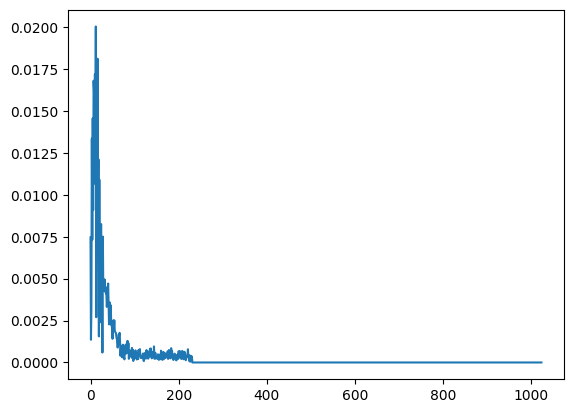

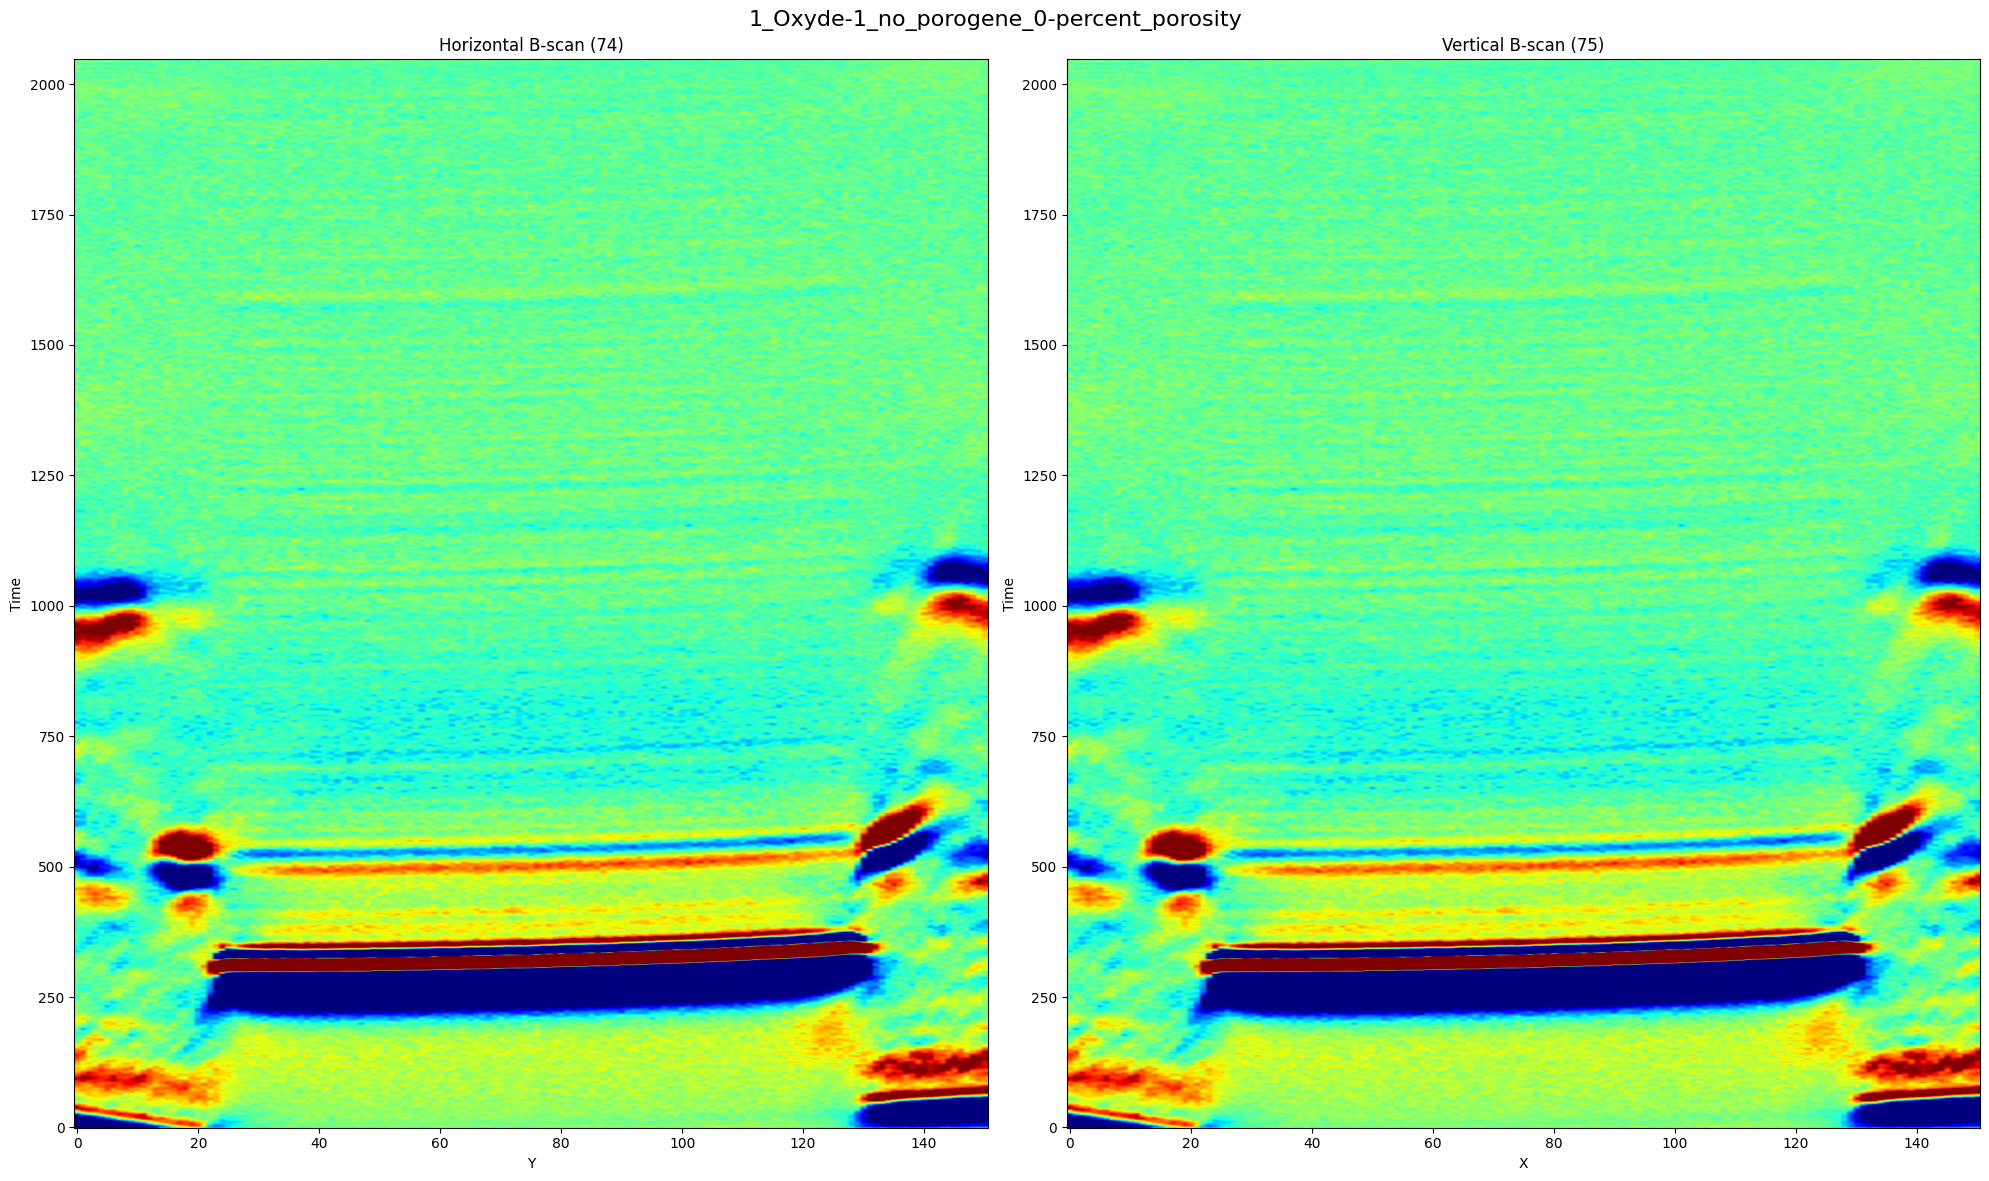

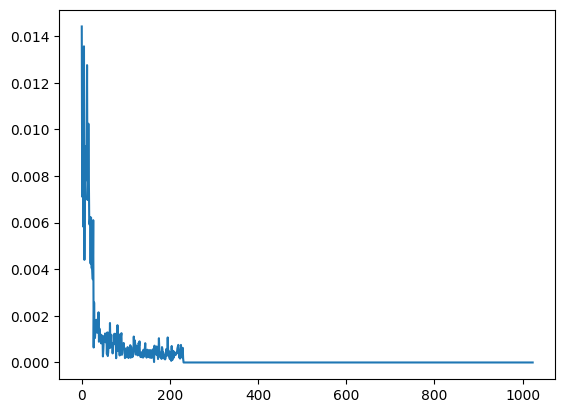

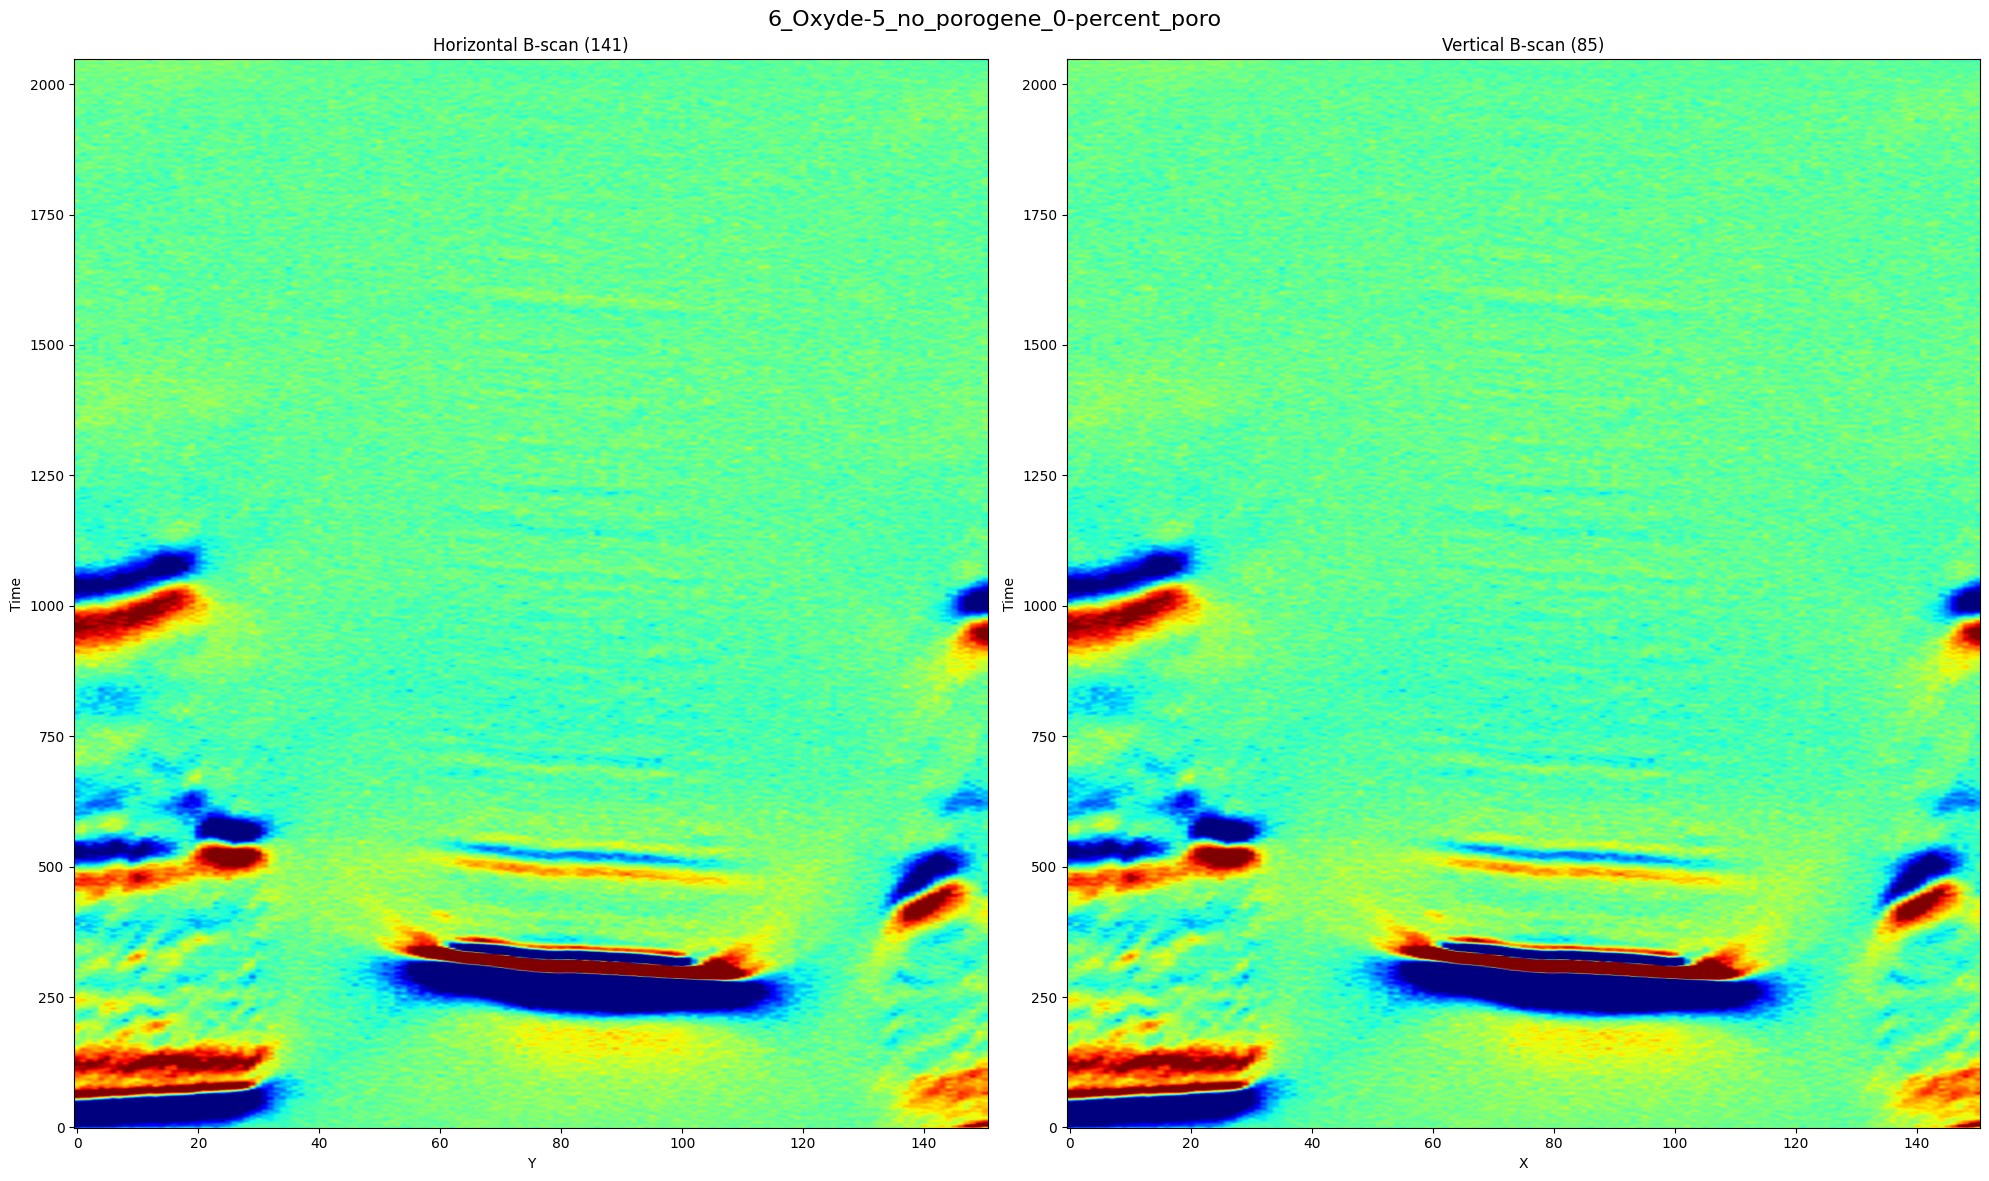

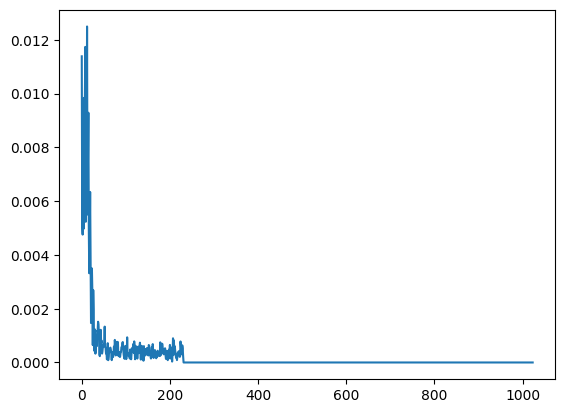

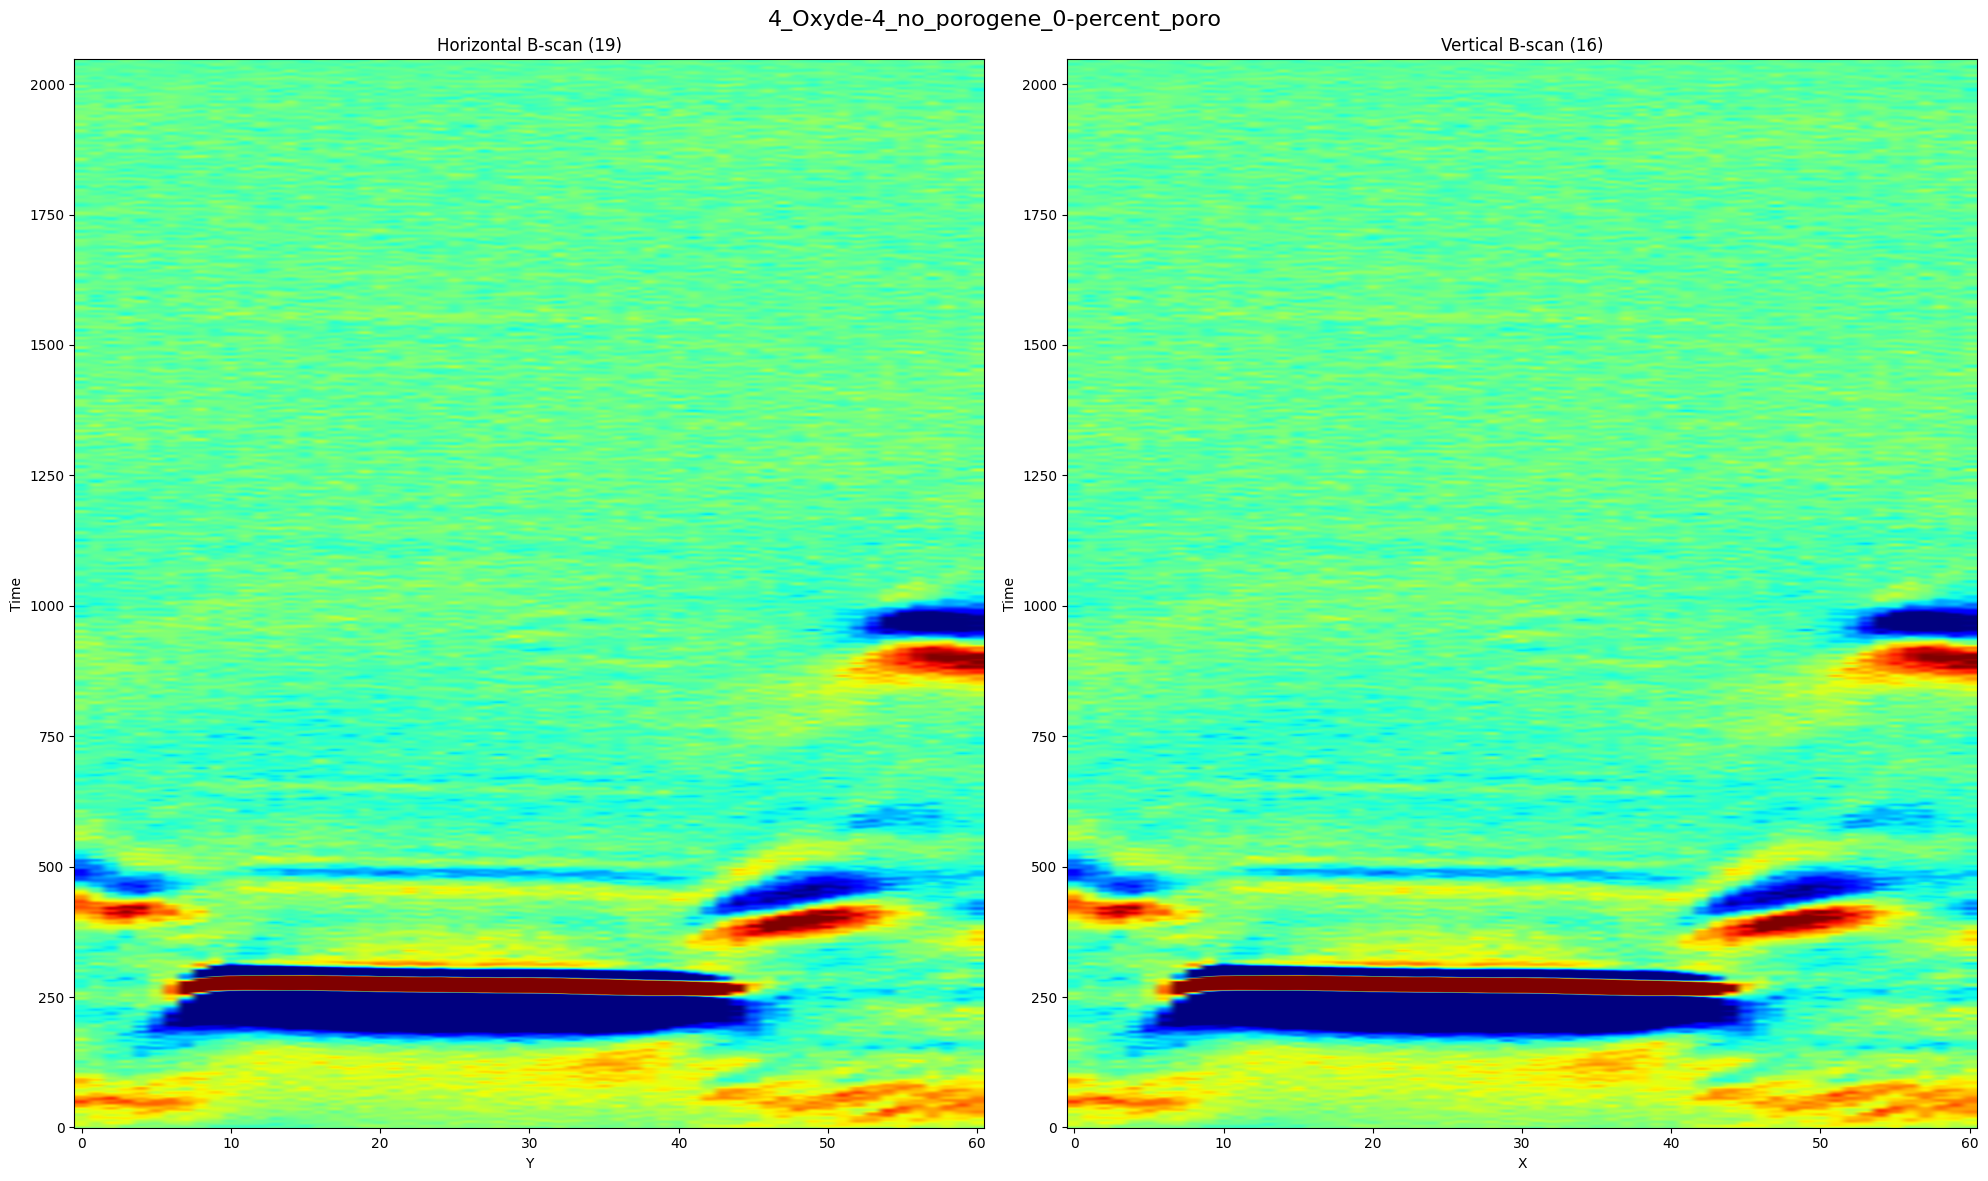

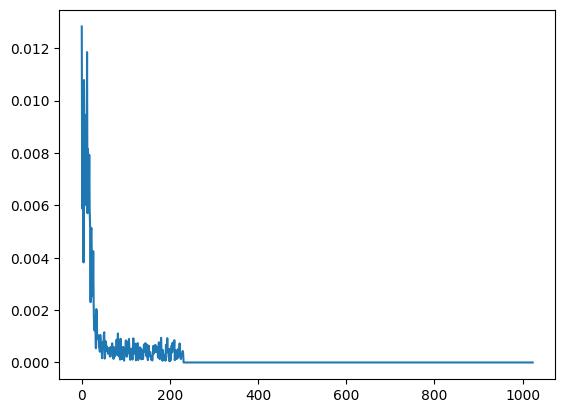

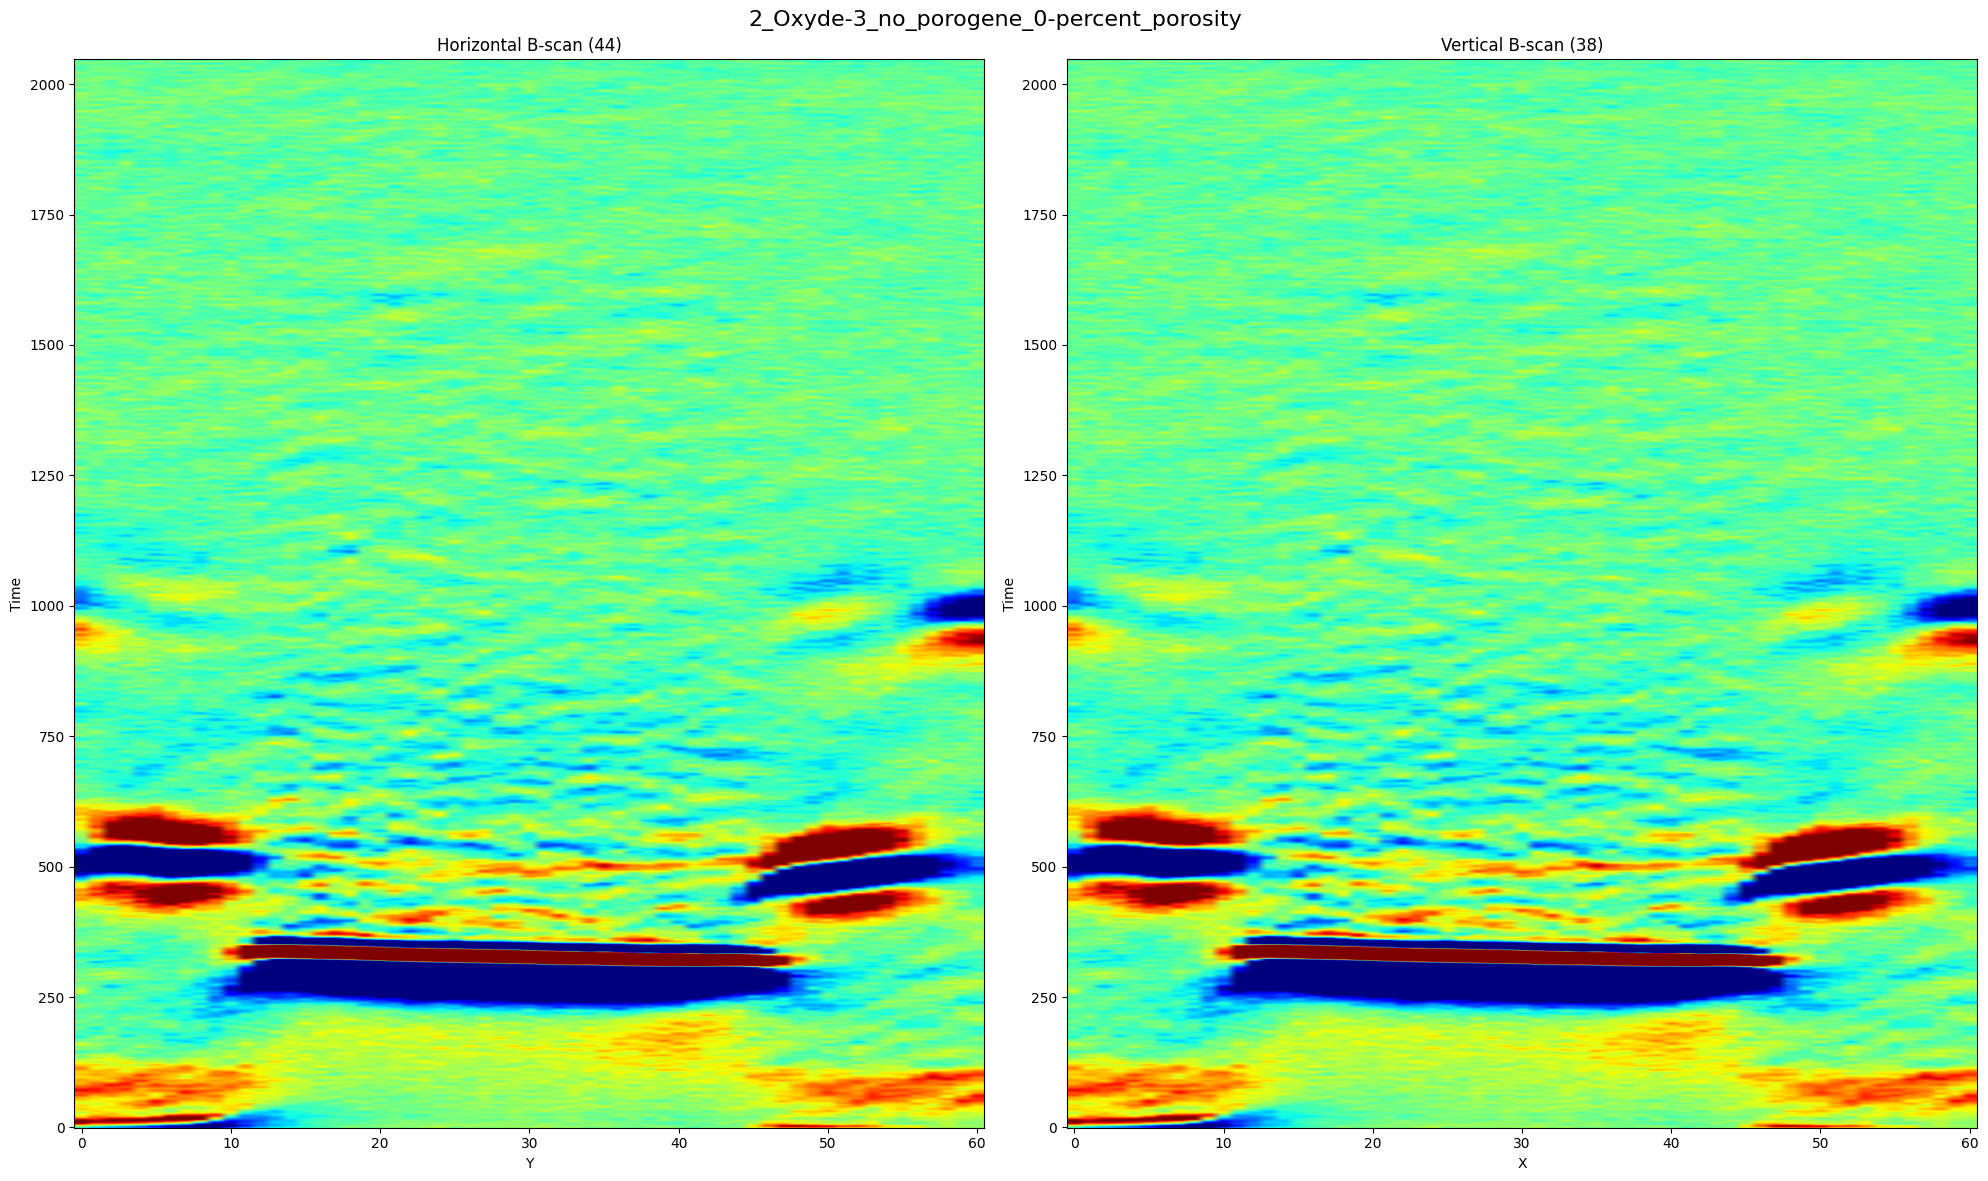

In [41]:
def bandpass_filter(signal_array, low_cut, high_cut, dt_ps):
    """
    Apply Fourier bandpass filter to each column waveform in signal_array.
    - low_cut, high_cut: in THz
    - dt_ps: time interval in picoseconds
    Returns: filtered signal_array with same shape
    """
    dt = dt_ps * 1e-12  # convert ps to seconds
    N = signal_array.shape[1]
    freqs = np.fft.fftfreq(N, dt)  # in Hz

    # Create bandpass mask in Hz
    mask = (np.abs(freqs) >= low_cut * 1e12) & (np.abs(freqs) <= high_cut * 1e12)

    # Apply filter to each column
    filtered = np.zeros_like(signal_array)
    for i in range(signal_array.shape[0]):
        fft_data = np.fft.fft(signal_array[i, :])
        fft_data[~mask] = 0
        filtered[i, :] = np.fft.ifft(fft_data).real

    plt.figure()
    plt.plot(2.0/N * np.abs(fft_data[0:N//2]))

    return filtered


dt_ps = 0.020464 

n_samples = ROI_arr.shape[0]
T = ROI_arr.shape[-1]
colors = [
    "#1f77b4",  # 14_composite_20-percent_poro
    "#ff7f0e",  # 13_Oxyde-2_raw_no_porogene
    "#2ca02c",  # 12_Oxyde-2_no_porogene_20-percent_poro
    "#d62728",  # 11_Oxyde-7_porogene_pression-P2_with_porogene
    "#342D69",  # 1_Oxyde-1_no_porogene_0-percent_porosity
    "#8c564b",  # 10_Oxyde-7_porogene_pression-P2_20-percent_poro_without_porogene
    "#e377c2",  # 9_Oxyde-6_raw_porogene_pression-P1_20-percent_poro_with_porogene
    "#7f7f7f",  # 8_Oxyde-6_porogene_pression-P1_20-percent_poro_without_porogene
    "#bcbd22",  # 7_Oxyde-5_raw_no_porogene
    "#474c99",  # 6_Oxyde-5_no_porogene_0-percent_poro
    "#393b79",  # 5_Oxyde-4_raw_no_porogene
    "#637939",  # 3_Oxyde-3_raw_no_porogene
    "#4b7ade",  # 4_Oxyde-4_no_porogene_0-percent_poro
    "#843c39",  # 3_Oxyde-3_raw_no_porogene_no_focus
    "#A0B9F0",  # 2_Oxyde-3_no_porogene_0-percent_porosity
    "#3182bd",  # 1_Oxyde-1_no_porogene_0-percent_porosity_old_holder
]

sample_list = [4, 9, 12, 14] #  Heated samples influence of diameter and height

for i in sample_list:

    # loadi into numpy array
    signal_array = np.loadtxt(file_list[i], delimiter=',')
    signal_array = signal_array[:, :].T

    low_cut = 0.0
    high_cut = 5.5
    filtered_signals = bandpass_filter(signal_array, low_cut=low_cut, high_cut=high_cut, dt_ps=dt_ps)

    datacube = filtered_signals.reshape(x_shape_list[i][1], x_shape_list[i][0], 2048) 

    coords = np.unravel_index(np.argmax(datacube), datacube.shape)

    vert_b_scan = datacube[:, coords[1], :].T
    hor_b_scan = datacube[coords[0], :, :].T

    fig, ax = plt.subplots(1,2, figsize=(20,12))
    ax[0].imshow(vert_b_scan, cmap='jet', origin='lower', aspect='auto', vmin=-0.08, vmax=0.1) #extent=[x_axis_mm[0], x_axis_mm[-1], y_axis_mm[0], y_axis_mm[-1]])

    ax[0].set_title(f"Horizontal B-scan ({coords[1]})")
    ax[0].set_xlabel("Y")
    ax[0].set_ylabel("Time")
    # plt.colorbar(label='Signal amplitude')

    ax[1].imshow(vert_b_scan, cmap='jet', origin='lower', aspect='auto', vmin=-0.08, vmax=0.1) #extent=[x_axis_mm[0], x_axis_mm[-1], y_axis_mm[0], y_axis_mm[-1]])

    ax[1].set_title(f"Vertical B-scan ({coords[0]})")
    ax[1].set_xlabel("X")
    ax[1].set_ylabel("Time")

    fig.suptitle(
        file_list[i].split("\\")[-1].removesuffix(".csv"),
        fontsize=16
    )
    fig.tight_layout()
    fig.show()
    